(sec-2-4)=
# 2.4 Probability and Statistics for Signals

No two heartbeats are identical. The RR interval of a healthy person at rest changes from beat to beat by tens of milliseconds, the amplitude of the R wave rises and falls with breathing, and every sample of the recording carries a little thermal noise from the amplifier and a little quantization noise from the converter. Some of this variability is a nuisance that we want to remove, and some of it, like heart rate variability, is the clinical information we are after. Either way we need a language for quantities that are not fixed numbers but vary in a way we can describe only on average. That language is probability.

In this section I collect the parts of probability and statistics that the rest of the book uses. We begin with random variables and their densities, define the moments that summarize them (mean, variance, skewness and kurtosis), and derive the statistics of three noise models that appear throughout biomedical engineering: Gaussian, uniform and Laplacian. We then see numerically why Gaussian noise is so common, distinguish uncorrelated from independent, and derive the most useful formula in experimental science, the $\sigma^2/N$ variance of a sample mean. The section ends with real recordings: muscle and electrode-motion noise from the MIT-BIH Noise Stress Test Database, needle EMG and resting EEG, whose histograms tell us which noise models are realistic. Random *processes*, sequences of random variables indexed by time, are the subject of [Section 7.1](../ch12_spectral_estimation/01_random_processes.ipynb).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
import mne
from scipy import signal, stats

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)
mne.set_log_level("ERROR")

(sec-2-4-1)=
## 2.4.1 Random Variables, Densities and Histograms

A **random variable** $X$ is a numerical outcome of an experiment whose result we cannot predict exactly: the voltage of the amplifier noise at a given instant, the next RR interval, the number of ectopic beats in an hour. Before the experiment, all we can state is how likely the different values are.

For a variable that takes continuous values, this is described by the **probability density function** (PDF) $f_X(x)$. Probabilities are areas under the density:

(eq-2-31)=
\begin{equation*}
P(a < X \le b) = \int_a^b f_X(x)\,dx, \qquad f_X(x) \ge 0, \qquad \int_{-\infty}^{\infty} f_X(x)\,dx = 1. \tag{2.31}
\end{equation*}

The density itself is not a probability; it has units of "probability per unit of $x$" (per mV for an ECG noise voltage), and it can exceed one. The **cumulative distribution function** (CDF) accumulates the density from the left, $F_X(x) = P(X \le x) = \int_{-\infty}^{x} f_X(u)\,du$. It rises from 0 to 1, and by the fundamental theorem of calculus $f_X = dF_X/dx$. Variables that take only discrete values, such as a count of beats, have a probability mass function $p_X(k) = P(X = k)$ instead, and every integral below becomes a sum.

In practice we never see $f_X$; we see $N$ samples $x_1, \ldots, x_N$. The **histogram** estimates the density: divide the axis into bins of width $\Delta$, count the samples $n_i$ falling into bin $i$, and plot $n_i/(N\Delta)$. Dividing by $N\Delta$ makes the total area one, so the histogram can be overlaid on a PDF (in NumPy and Matplotlib this is `density=True`). The **empirical CDF** is even simpler: sort the samples and plot the fraction of samples at or below each value. It needs no bin width and converges to $F_X$ as $N$ grows.

The cell below draws 2000 samples of amplifier noise, modelled as Gaussian with a standard deviation of 10 µV, and compares both estimates with the true curves.

fraction of samples within +/-1 sigma: 0.679  (Gaussian: 0.683)
largest gap between empirical and true CDF: 0.033


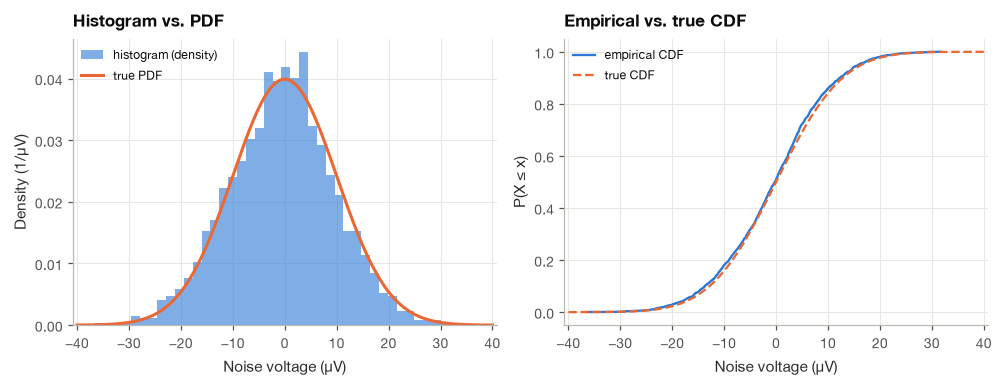

In [2]:
sigma_amp = 10.0                                         # µV
noise = rng.normal(0.0, sigma_amp, 2000)

def ecdf(x):
    """Empirical CDF: sorted samples and the fraction of samples at or below each."""
    xs = np.sort(x)
    return xs, np.arange(1, xs.size + 1) / xs.size

xs, Fs = ecdf(noise)
ks = np.max(np.abs(Fs - stats.norm.cdf(xs, scale=sigma_amp)))
print(f"fraction of samples within +/-1 sigma: {np.mean(np.abs(noise) < sigma_amp):.3f}  (Gaussian: 0.683)")
print(f"largest gap between empirical and true CDF: {ks:.3f}")

grid = np.linspace(-40, 40, 400)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].hist(noise, bins=40, density=True, color=C[0], alpha=0.6, label="histogram (density)")
axes[0].plot(grid, stats.norm.pdf(grid, scale=sigma_amp), color=C[1], lw=2, label="true PDF")
axes[0].set(xlabel="Noise voltage (µV)", ylabel="Density (1/µV)", title="Histogram vs. PDF")
axes[0].legend(loc="upper left", fontsize=8)
axes[1].plot(xs, Fs, color=C[0], lw=1.5, label="empirical CDF")
axes[1].plot(grid, stats.norm.cdf(grid, scale=sigma_amp), color=C[1], lw=1.5, ls="--", label="true CDF")
axes[1].set(xlabel="Noise voltage (µV)", ylabel="P(X ≤ x)", title="Empirical vs. true CDF")
axes[1].legend(loc="upper left", fontsize=8)
plt.show()

(sec-2-4-2)=
## 2.4.2 Moments: Mean, Variance, Skewness and Kurtosis

A density contains everything there is to know about a random variable, but a few numbers usually say enough. They are all built from the **expectation**, the density-weighted average of a function of $X$:

$$
\mathbb{E}[g(X)] = \int_{-\infty}^{\infty} g(x)\,f_X(x)\,dx .
$$

Because the integral is linear, so is the expectation: $\mathbb{E}[aX + b] = a\,\mathbb{E}[X] + b$ for constants $a$ and $b$. We will use this property constantly.

The **mean** $\mu = \mathbb{E}[X]$ locates the distribution; for an ECG electrode it is the DC offset. The **variance** measures spread around the mean, $\sigma^2 = \mathbb{E}[(X - \mu)^2]$, and its square root $\sigma$, the **standard deviation**, has the same units as $X$. For a zero-mean noise, $\sigma$ is the RMS value and $\sigma^2$ the average power. Expanding the square and applying linearity gives a formula that is often easier to use:

(eq-2-32)=
\begin{equation*}
\sigma^2 = \mathbb{E}[X^2 - 2\mu X + \mu^2] = \mathbb{E}[X^2] - 2\mu\,\mathbb{E}[X] + \mu^2 = \mathbb{E}[X^2] - \mu^2 . \tag{2.32}
\end{equation*}

In words, the total power equals the AC power plus the DC power, the same split we make for deterministic signals in Section 3.4. Scaling a variable scales its spread: $\operatorname{Var}(aX + b) = \mathbb{E}[(aX + b - a\mu - b)^2] = a^2\sigma^2$, so an amplifier with gain $a$ multiplies the noise standard deviation by $|a|$, and adding an offset changes nothing.

Two further moments describe the shape. Using the standardized variable $Z = (X - \mu)/\sigma$, which has zero mean and unit variance,

(eq-2-33)=
\begin{equation*}
\text{skewness} = \mathbb{E}[Z^3], \qquad \text{kurtosis} = \mathbb{E}[Z^4], \qquad \text{excess kurtosis} = \mathbb{E}[Z^4] - 3. \tag{2.33}
\end{equation*}

The skewness is zero for a symmetric density and positive when the right tail is longer. The kurtosis measures the weight of the tails. A Gaussian has kurtosis 3 (we prove it below), so the **excess kurtosis** compares a density with the Gaussian: positive values mean heavier tails and a sharper peak, typical of spiky signals such as EMG; negative values mean light tails, as in a uniform density. SciPy's `stats.kurtosis` returns the excess kurtosis by default.

From samples, we estimate the moments by replacing expectations with averages: $\bar{x} = \frac{1}{N}\sum_i x_i$ for the mean, and for the variance

$$
s^2 = \frac{1}{N - 1}\sum_{i=1}^{N} (x_i - \bar{x})^2 .
$$

The divisor $N - 1$ rather than $N$ compensates for measuring the spread around the sample mean, which is always closer to the data than the true mean; we prove this in [Section 2.4.6](#sec-2-4-6). In NumPy, `np.var(x, ddof=1)` uses $N - 1$ and the default `ddof=0` uses $N$.

In [3]:
def moments(x):
    """Sample mean, standard deviation, skewness and excess kurtosis, equations (2.43)-(2.44)."""
    mu = x.mean()
    sd = np.sqrt(np.sum((x - mu) ** 2) / (x.size - 1))
    z = (x - mu) / x.std()
    return mu, sd, np.mean(z ** 3), np.mean(z ** 4) - 3

x = rng.exponential(scale=2.0, size=200_000)             # a skewed test variable
mu, sd, sk, ku = moments(x)
print(f"ours : mean {mu:.4f}, sd {sd:.4f}, skewness {sk:.4f}, excess kurtosis {ku:.4f}")
print(f"scipy: mean {x.mean():.4f}, sd {x.std(ddof=1):.4f}, skewness {stats.skew(x):.4f}, "
      f"excess kurtosis {stats.kurtosis(x):.4f}")
print("exact: mean 2, sd 2, skewness 2, excess kurtosis 6 for the exponential density")

ours : mean 1.9980, sd 2.0026, skewness 2.0175, excess kurtosis 6.1854
scipy: mean 1.9980, sd 2.0026, skewness 2.0175, excess kurtosis 6.1854
exact: mean 2, sd 2, skewness 2, excess kurtosis 6 for the exponential density


(sec-2-4-3)=
## 2.4.3 Three Noise Models

Three densities cover most noise models in this book. To compare their shapes fairly, we will give each one the same variance $\sigma^2$.

### The Gaussian density

The Gaussian, or normal, density with mean $\mu$ and variance $\sigma^2$ is

(eq-2-34)=
\begin{equation*}
f_X(x) = \frac{1}{\sigma\sqrt{2\pi}}\,\exp\!\left(-\frac{(x - \mu)^2}{2\sigma^2}\right), \qquad X \sim \mathcal{N}(\mu, \sigma^2). \tag{2.34}
\end{equation*}

The constant in front comes straight from the Gaussian integral (2.27) of [Section 2.3.6](04_calculus_for_signals.ipynb#sec-2-3-6), which gives $\int e^{-(x-\mu)^2/(2\sigma^2)}dx = \sigma\sqrt{2\pi}$, so the area is one. That the parameter $\sigma^2$ really is the variance takes one integration by parts. With $s = x - \mu$,

$$
\begin{aligned}
\mathbb{E}[(X - \mu)^2] &= \frac{1}{\sigma\sqrt{2\pi}}\int_{-\infty}^{\infty} s \cdot s\,e^{-s^2/(2\sigma^2)}\,ds \\
&= \frac{1}{\sigma\sqrt{2\pi}}\left(\Big[-\sigma^2 s\,e^{-s^2/(2\sigma^2)}\Big]_{-\infty}^{\infty} + \sigma^2\int_{-\infty}^{\infty} e^{-s^2/(2\sigma^2)}\,ds\right) \\
&= \frac{1}{\sigma\sqrt{2\pi}}\left(0 + \sigma^2\cdot\sigma\sqrt{2\pi}\right) = \sigma^2,
\end{aligned}
$$

where we took $f = s$ and $g' = s\,e^{-s^2/(2\sigma^2)}$, so that $g = -\sigma^2 e^{-s^2/(2\sigma^2)}$. Repeating the trick once more gives $\mathbb{E}[(X - \mu)^4] = 3\sigma^4$, hence a kurtosis of 3 and an excess kurtosis of zero. The Gaussian is the model for thermal noise in electrodes and amplifiers and, as we will see, for any noise made of many small independent contributions. About 68% of its probability lies within $\pm\sigma$ of the mean, 95% within $\pm 1.96\sigma$ and 99.7% within $\pm 3\sigma$.

### The uniform density and quantization noise

An analog-to-digital converter rounds each voltage to the nearest of a set of levels spaced $\Delta$ apart. If the signal moves over many levels, the rounding error $e$ is equally likely to be anywhere between $-\Delta/2$ and $\Delta/2$, so its density is the constant $1/\Delta$ on that interval. Its mean is zero by symmetry and its variance is

(eq-2-35)=
\begin{equation*}
\sigma_e^2 = \int_{-\Delta/2}^{\Delta/2} e^2\,\frac{1}{\Delta}\,de = \frac{1}{\Delta}\left[\frac{e^3}{3}\right]_{-\Delta/2}^{\Delta/2} = \frac{1}{\Delta}\cdot\frac{2}{3}\cdot\frac{\Delta^3}{8} = \frac{\Delta^2}{12}. \tag{2.35}
\end{equation*}

The MIT-BIH recordings were digitized with 200 converter units per millivolt, so $\Delta = 5$ µV and the quantization noise has a standard deviation of $5/\sqrt{12} \approx 1.4$ µV, far below the other noise sources. Its fourth moment is $\Delta^4/80$, giving a kurtosis of $(\Delta^4/80)/(\Delta^4/144) = 1.8$ and an excess kurtosis of $-1.2$: the uniform density has no tails at all. Quantization is treated in detail in Section 9.4.

### The Laplacian density

The Laplacian density decays exponentially in $|x|$ instead of in $x^2$:

(eq-2-36)=
\begin{equation*}
f_X(x) = \frac{1}{2b}\,e^{-|x|/b}, \qquad \sigma^2 = 2b^2, \qquad \text{excess kurtosis} = 3. \tag{2.36}
\end{equation*}

The moments follow from the integral $\int_0^\infty t^n e^{-t/b}\,dt = n!\,b^{n+1}$, which is equation (2.26) of the previous section generalized by repeated integration by parts (exercise 3 there). Because the density is even, $\mathbb{E}[X^2] = 2\cdot\frac{1}{2b}\int_0^\infty x^2 e^{-x/b}dx = \frac{1}{b}\cdot 2b^3 = 2b^2$, and likewise $\mathbb{E}[X^4] = \frac{1}{b}\cdot 24 b^5 = 24 b^4$, so the kurtosis is $24b^4/(2b^2)^2 = 6$. The sharp peak and heavy tails make the Laplacian a better model than the Gaussian for signals that are mostly quiet with occasional bursts, such as EMG and the coefficients of wavelet transforms (which is why wavelet denoising in [Section 14.2](../ch24_wavelets/02_wavelet_denoising.ipynb) uses soft thresholding).

In [4]:
sigma = 1.0
models = {
    "Gaussian":  stats.norm(scale=sigma),
    "uniform":   stats.uniform(loc=-np.sqrt(3) * sigma, scale=2 * np.sqrt(3) * sigma),   # Delta = sqrt(12) sigma
    "Laplacian": stats.laplace(scale=sigma / np.sqrt(2)),                               # b = sigma / sqrt(2)
}
rows = []
for name, dist in models.items():
    x = dist.rvs(size=400_000, random_state=rng)
    _, sd, sk, ku = moments(x)
    rows.append({"model": name, "sample sd": sd, "sample excess kurtosis": ku,
                 "theory excess kurtosis": float(dist.stats(moments="k")),
                 "P(|X| > 3 sigma)": np.mean(np.abs(x) > 3 * sigma)})
print(pd.DataFrame(rows).set_index("model").to_string(float_format="{:.4f}".format))

           sample sd  sample excess kurtosis  theory excess kurtosis  P(|X| > 3 sigma)
model                                                                                 
Gaussian      0.9997                 -0.0009                  0.0000            0.0027
uniform       1.0001                 -1.2007                 -1.2000            0.0000
Laplacian     0.9961                  2.9394                  3.0000            0.0140


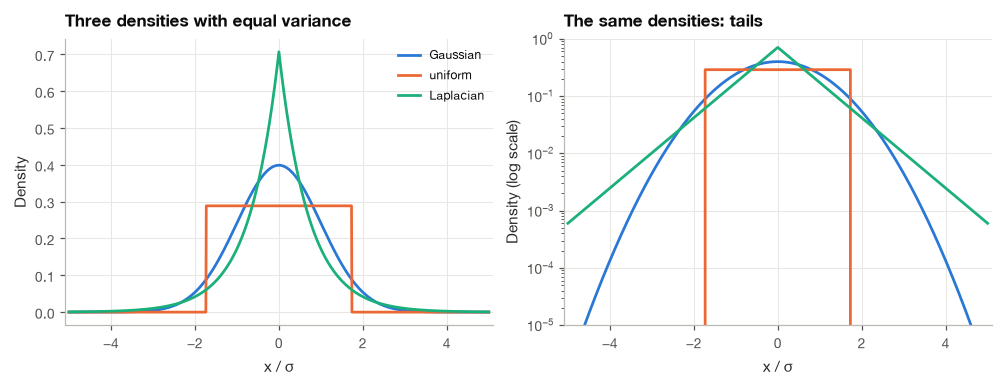

In [5]:
grid = np.linspace(-5, 5, 1001)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for k, (name, dist) in enumerate(models.items()):
    axes[0].plot(grid, dist.pdf(grid), color=C[k], lw=1.8, label=name)
    axes[1].semilogy(grid, dist.pdf(grid), color=C[k], lw=1.8, label=name)
axes[0].set(xlabel="x / σ", ylabel="Density", title="Three densities with equal variance")
axes[1].set(xlabel="x / σ", ylabel="Density (log scale)", ylim=(1e-5, 1), title="The same densities: tails")
axes[0].legend(loc="upper right", fontsize=8)
plt.show()

On a linear scale the three densities look broadly similar. The logarithmic scale is where they differ: the Gaussian log-density is a parabola that plunges quickly, the Laplacian falls along straight lines, and the uniform stops abruptly. With the same variance, a Laplacian variable exceeds $3\sigma$ more than four times as often as a Gaussian one. A detector that sets its threshold at $3\sigma$ under a Gaussian assumption will raise many more false alarms on Laplacian-like noise than its designer expects.

(sec-2-4-4)=
## 2.4.4 Why Noise Is Often Gaussian: The Central Limit Theorem

The voltage measured at a scalp electrode is the sum of the activity of millions of neurons, and thermal noise in a resistor is the sum of the motions of an enormous number of electrons. The **central limit theorem** explains why such sums are nearly Gaussian, whatever the distribution of the individual contributions.

Let $X_1, \ldots, X_N$ be independent, each with mean $\mu$ and variance $\sigma^2$. Their sum $S_N$ has mean $N\mu$ and, as we prove in the next subsection, variance $N\sigma^2$. The theorem states that the standardized sum

$$
Z_N = \frac{S_N - N\mu}{\sigma\sqrt{N}}
$$

has a distribution that approaches $\mathcal{N}(0, 1)$ as $N \to \infty$. The proof requires characteristic functions (Fourier transforms of densities, see {cite:t}`papoulis2002`), so I show it numerically instead. A clean way to measure the approach is through the excess kurtosis, which for a sum of $N$ independent identical terms equals the excess kurtosis of one term divided by $N$. Starting from the uniform density ($-1.2$), the excess kurtosis of the sum should be $-0.6$ for $N = 2$, $-0.3$ for $N = 4$ and $-0.075$ for $N = 16$.

N =  1: excess kurtosis -1.198  (theory -1.200)
N =  2: excess kurtosis -0.596  (theory -0.600)
N =  4: excess kurtosis -0.312  (theory -0.300)
N = 16: excess kurtosis -0.080  (theory -0.075)


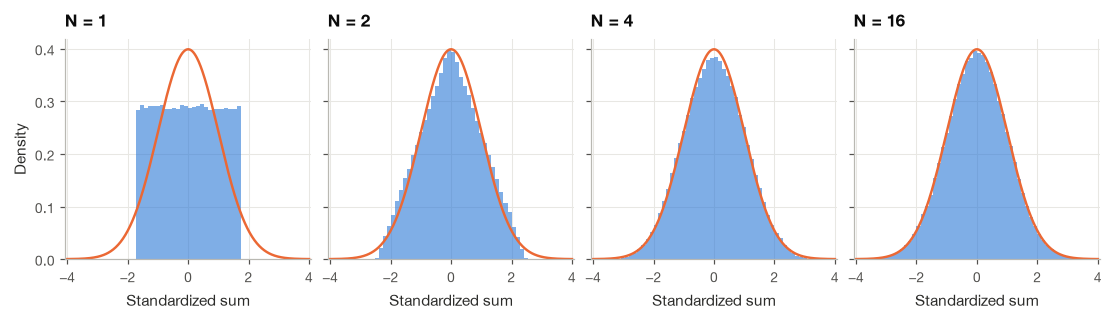

In [6]:
Ns = (1, 2, 4, 16)
trials = 200_000
fig, axes = plt.subplots(1, 4, figsize=(10, 2.8), sharey=True)
grid = np.linspace(-4, 4, 400)
for ax, N in zip(axes, Ns):
    u = rng.uniform(-0.5, 0.5, size=(trials, N))
    z = u.sum(axis=1) / np.sqrt(N / 12)                  # standardize: each term has variance 1/12
    ax.hist(z, bins=60, range=(-4, 4), density=True, color=C[0], alpha=0.6)
    ax.plot(grid, stats.norm.pdf(grid), color=C[1], lw=1.6)
    ax.set(xlabel="Standardized sum", title=f"N = {N}")
    print(f"N = {N:2d}: excess kurtosis {stats.kurtosis(z):+.3f}  (theory {-1.2 / N:+.3f})")
axes[0].set_ylabel("Density")
plt.show()

Already at $N = 4$ the histogram of a sum of uniform variables is hard to tell from the Gaussian curve by eye. The theorem has limits that matter for physiological data. It requires many contributions of comparable size; when one or a few sources dominate, as when a needle electrode sits next to a single motor unit, the sum keeps the shape of those sources and is far from Gaussian. We will see this in the EMG data at the end of the section.

(sec-2-4-5)=
## 2.4.5 Covariance, Correlation and Independence

With two random variables we need their **joint density** $f_{XY}(x, y)$, and the most important summary of how they vary together is the **covariance**

(eq-2-37)=
\begin{equation*}
\operatorname{Cov}(X, Y) = \mathbb{E}\big[(X - \mu_X)(Y - \mu_Y)\big] = \mathbb{E}[XY] - \mu_X\mu_Y, \qquad
\rho_{XY} = \frac{\operatorname{Cov}(X, Y)}{\sigma_X\,\sigma_Y}. \tag{2.37}
\end{equation*}

The second form follows by expanding the product, exactly as in equation [(2.32)](#eq-2-32). The **correlation coefficient** $\rho_{XY}$ is the probabilistic counterpart of the cosine between centred vectors in [Section 2.2.3](03_signals_as_vectors.ipynb#sec-2-2-3), and the Cauchy–Schwarz inequality, which holds for expectations just as for sums, guarantees $|\rho_{XY}| \le 1$.

Covariance appears whenever we add random signals. Expanding the square,

(eq-2-38)=
\begin{equation*}
\operatorname{Var}(X + Y) = \mathbb{E}\big[((X - \mu_X) + (Y - \mu_Y))^2\big] = \sigma_X^2 + \sigma_Y^2 + 2\operatorname{Cov}(X, Y). \tag{2.38}
\end{equation*}

Powers add only when the covariance is zero, which is the probabilistic version of the Pythagorean theorem of [Section 2.2.2](03_signals_as_vectors.ipynb#sec-2-2-2).

**Independence implies zero covariance.** Two variables are **independent** when their joint density factors, $f_{XY}(x, y) = f_X(x)\,f_Y(y)$: knowing $X$ tells us nothing about $Y$. Then the double integral for $\mathbb{E}[XY]$ separates,

$$
\mathbb{E}[XY] = \iint xy\,f_X(x)f_Y(y)\,dx\,dy = \int x f_X(x)\,dx \int y f_Y(y)\,dy = \mu_X\mu_Y,
$$

so $\operatorname{Cov}(X, Y) = 0$. Independent variables are uncorrelated, and by equation (2.38) the variances of independent noise sources add. Amplifier noise and power-line interference come from different physical mechanisms, so their powers add in a recording.

**The converse is false.** Let $X \sim \mathcal{N}(0, 1)$ and $Y = X^2$. Then $Y$ is completely determined by $X$, as dependent as two variables can be. Yet

$$
\operatorname{Cov}(X, Y) = \mathbb{E}[X\cdot X^2] - \mathbb{E}[X]\,\mathbb{E}[X^2] = \mathbb{E}[X^3] - 0 = 0,
$$

because the third moment of a symmetric density vanishes (the integrand $x^3 f_X(x)$ is odd). Correlation detects only *linear* dependence. Uncorrelated noise sources need not be independent, and a correlation coefficient near zero between two physiological signals does not prove that they are unrelated. The coupling between heart rate and respiration, for instance, can be strongly nonlinear. Methods that look beyond second-order statistics, such as independent component analysis (Section 25.2) and the entropy measures of Chapter 26, exist for exactly this reason.

rho(x, x^2)         = +0.040   (dependent but uncorrelated)
rho(x, 0.8x + 0.6n) = +0.793   (theory +0.800)
Var(x + y) = 3.575; sigma_x^2 + sigma_y^2 + 2 Cov = 3.575


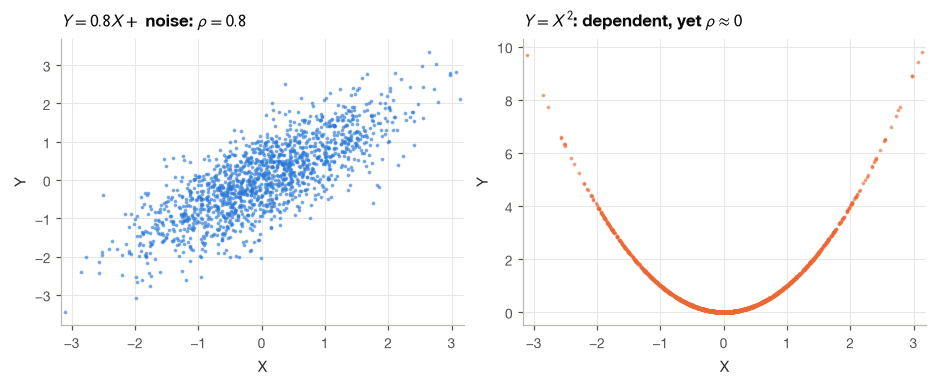

In [7]:
x = rng.standard_normal(5000)
y_square = x ** 2
y_linear = 0.8 * x + 0.6 * rng.standard_normal(x.size)
print(f"rho(x, x^2)         = {np.corrcoef(x, y_square)[0, 1]:+.3f}   (dependent but uncorrelated)")
print(f"rho(x, 0.8x + 0.6n) = {np.corrcoef(x, y_linear)[0, 1]:+.3f}   (theory +0.800)")
v = x + y_linear
print(f"Var(x + y) = {v.var():.3f}; sigma_x^2 + sigma_y^2 + 2 Cov = "
      f"{x.var() + y_linear.var() + 2 * np.cov(x, y_linear, ddof=0)[0, 1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.4), sharex=True)
axes[0].plot(x[:1500], y_linear[:1500], ".", color=C[0], ms=3, alpha=0.5)
axes[0].set(xlabel="X", ylabel="Y", title=r"$Y = 0.8X + $ noise: $\rho = 0.8$")
axes[1].plot(x[:1500], y_square[:1500], ".", color=C[1], ms=3, alpha=0.5)
axes[1].set(xlabel="X", ylabel="Y", title=r"$Y = X^2$: dependent, yet $\rho \approx 0$")
plt.show()

(sec-2-4-6)=
## 2.4.6 The Sample Mean and Its Uncertainty

Suppose we measure $N$ independent values $X_1, \ldots, X_N$ of the same quantity, each with mean $\mu$ and variance $\sigma^2$: the RR interval of $N$ beats, the amplitude of an evoked potential on $N$ trials, the ECG at the same point of $N$ aligned beats. We estimate $\mu$ by the sample mean $\bar{X} = \frac{1}{N}\sum_i X_i$. How good is this estimate?

**Step 1: the sample mean is unbiased.** By linearity, $\mathbb{E}[\bar{X}] = \frac{1}{N}\sum_i \mathbb{E}[X_i] = \frac{1}{N}\cdot N\mu = \mu$. On average, the estimate is right.

**Step 2: its variance.** Applying equation (2.38) repeatedly to a sum of $N$ terms, the variance of the sum is the sum of all variances plus twice all pairwise covariances. For independent (or merely uncorrelated) terms every covariance vanishes, and since $\operatorname{Var}(aX) = a^2\operatorname{Var}(X)$ with $a = 1/N$,

(eq-2-39)=
\begin{equation*}
\operatorname{Var}(\bar{X}) = \frac{1}{N^2}\sum_{i=1}^{N}\operatorname{Var}(X_i) = \frac{1}{N^2}\cdot N\sigma^2 = \frac{\sigma^2}{N}, \qquad \operatorname{SE}(\bar{X}) = \frac{\sigma}{\sqrt{N}}. \tag{2.39}
\end{equation*}

The **standard error** falls as $1/\sqrt{N}$. To halve the uncertainty we need four times as many measurements. This is the principle behind **signal averaging** ([Section 10.1](../ch16_noise_removal/01_signal_averaging.ipynb)): averaging 100 aligned beats or evoked responses reduces the noise standard deviation tenfold, which is how brainstem auditory potentials of a few hundred nanovolts are pulled out of EEG background of tens of microvolts.

**Step 3: why $s^2$ divides by $N - 1$.** Writing $X_i - \bar{X} = (X_i - \mu) - (\bar{X} - \mu)$ and expanding, the cross terms add up to $-2N(\bar{X} - \mu)^2$, so

$$
\sum_{i=1}^{N}(X_i - \bar{X})^2 = \sum_{i=1}^{N}(X_i - \mu)^2 - N(\bar{X} - \mu)^2 .
$$

Taking expectations and using equation (2.39) for the last term gives $N\sigma^2 - N\cdot\sigma^2/N = (N - 1)\sigma^2$. Dividing the sum of squares by $N - 1$ therefore gives an unbiased estimate of $\sigma^2$.

**Step 4: a confidence interval.** By the central limit theorem, $\bar{X}$ is approximately Gaussian for moderate $N$ even when the $X_i$ are not, so with probability about 0.95 it lies within $1.96\,\sigma/\sqrt{N}$ of $\mu$. Turning the statement around gives the 95% **confidence interval**

(eq-2-40)=
\begin{equation*}
\bar{x} \pm 1.96\,\frac{s}{\sqrt{N}} . \tag{2.40}
\end{equation*}

For small $N$, replacing $\sigma$ by $s$ adds uncertainty and the factor 1.96 should be replaced by the corresponding quantile of Student's $t$ distribution with $N - 1$ degrees of freedom (2.06 for $N = 25$). The interpretation is easy to get wrong: if we repeated the whole experiment many times, about 95% of the intervals computed this way would contain the true mean. We check that claim by simulation with Laplacian data, which are far from Gaussian.

In [8]:
N, n_experiments = 25, 20_000
mu_true, b = 0.0, 1.0
data = rng.laplace(mu_true, b, size=(n_experiments, N))
xbar = data.mean(axis=1)
s = data.std(axis=1, ddof=1)
t_crit = stats.t.ppf(0.975, df=N - 1)
covered = np.abs(xbar - mu_true) <= t_crit * s / np.sqrt(N)
print(f"spread of sample means: {xbar.std():.4f}  (sigma/sqrt(N) = {np.sqrt(2) * b / np.sqrt(N):.4f})")
print(f"mean of s^2 (ddof=1)  : {np.mean(s**2):.4f}  (sigma^2 = {2 * b**2:.4f})")
print(f"t quantile for N = {N}: {t_crit:.3f}")
print(f"coverage of the 95% interval: {covered.mean():.3f}")

spread of sample means: 0.2811  (sigma/sqrt(N) = 0.2828)
mean of s^2 (ddof=1)  : 1.9981  (sigma^2 = 2.0000)
t quantile for N = 25: 2.064
coverage of the 95% interval: 0.954


### The mean heart rate of record 100

As a real example we estimate the mean RR interval of record 100 from the annotated beats, and watch the confidence interval shrink as we include more beats.

2272 RR intervals: mean 794.6 ms, sd 48.8 ms
95% CI of the mean RR: 792.6 to 796.6 ms
mean heart rate 60/mean(RR): 75.5 bpm
correlation between successive RR intervals: 0.16


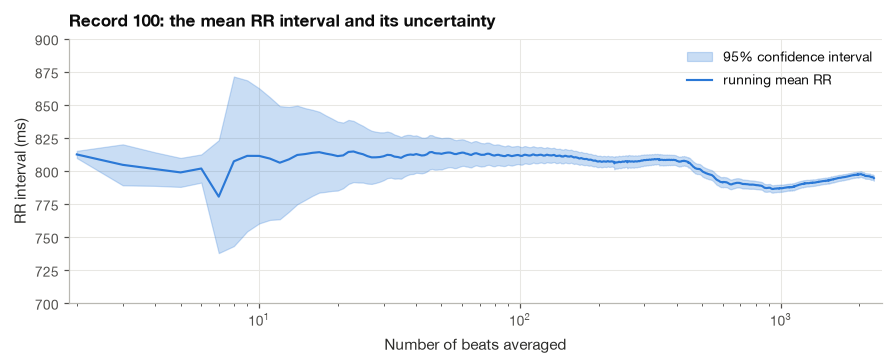

In [9]:
ann = wfdb.rdann("../data/mitdb/100", "atr")
is_beat = np.isin(ann.symbol, list("NLRBAaJSVrFejnE/fQ"))
rr = np.diff(ann.sample[is_beat]) / 360.0                # seconds
n_beats = np.arange(2, rr.size + 1)
run_mean = np.cumsum(rr)[1:] / n_beats
run_sd = np.array([rr[:k].std(ddof=1) for k in n_beats])
half_width = 1.96 * run_sd / np.sqrt(n_beats)

print(f"{rr.size} RR intervals: mean {rr.mean() * 1000:.1f} ms, sd {rr.std(ddof=1) * 1000:.1f} ms")
print(f"95% CI of the mean RR: {1000 * (rr.mean() - half_width[-1]):.1f} to {1000 * (rr.mean() + half_width[-1]):.1f} ms")
print(f"mean heart rate 60/mean(RR): {60 / rr.mean():.1f} bpm")
print(f"correlation between successive RR intervals: {np.corrcoef(rr[:-1], rr[1:])[0, 1]:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.fill_between(n_beats, 1000 * (run_mean - half_width), 1000 * (run_mean + half_width),
                color=C[0], alpha=0.25, label="95% confidence interval")
ax.plot(n_beats, 1000 * run_mean, color=C[0], lw=1.4, label="running mean RR")
ax.set(xscale="log", xlabel="Number of beats averaged", ylabel="RR interval (ms)",
       title="Record 100: the mean RR interval and its uncertainty", ylim=(700, 900))
ax.legend(loc="upper right")
plt.show()

The interval narrows as $1/\sqrt{N}$, and after the whole 30-minute record the mean RR interval is known to within about 2 ms. There is a catch that I want to flag clearly. Equation (2.39) assumed uncorrelated samples, and successive RR intervals are positively correlated (here about 0.16, and much more for slow trends over minutes). Positive correlation adds positive covariance terms to the variance of the mean, so the true uncertainty is larger than the formula suggests. The same issue arises whenever we treat neighbouring samples of a signal as independent; [Section 7.1](../ch12_spectral_estimation/01_random_processes.ipynb) shows how to account for it with the autocorrelation function.

(sec-2-4-7)=
## 2.4.7 Noise Statistics of Real Recordings, Step by Step

The noise models of [Section 2.4.3](#sec-2-4-3) are idealizations. Real biomedical noise can be checked against them, and the result guides the choice of method: a Gaussian assumption leads to least-squares and Wiener filtering, heavy tails suggest median filters and robust statistics. We examine five recordings.

### Step 1: Load the recordings

The MIT-BIH Noise Stress Test Database {cite:p}`moody1984` contains three noise records made with electrodes placed on the limbs of active volunteers where the ECG is barely visible: muscle (EMG) artifact `ma`, electrode motion artifact `em` and baseline wander `bw`. We take the first five minutes of channel 1 of `ma` and `em`, together with needle EMG from a healthy tibialis anterior muscle and from a patient with neuropathy {cite:p}`goldberger2000`, and the occipital channel Oz of a resting EEG with the eyes closed from the EEG Motor Movement/Imagery Database {cite:p}`schalk2004`.

In [10]:
records = {}
for name in ("ma", "em"):
    rec = wfdb.rdrecord(f"../data/nstdb/{name}", sampto=300 * 360)
    records[f"ECG noise: {name}"] = (rec.p_signal[:, 0], rec.fs, "mV")
for name in ("emg_healthy", "emg_neuropathy"):
    rec = wfdb.rdrecord(f"../data/emgdb/{name}")
    records[f"needle EMG: {name[4:]}"] = (rec.p_signal[:, 0], rec.fs, "mV")
raw = mne.io.read_raw_edf("../data/eegmmidb/S001R02.edf", preload=True)
mne.datasets.eegbci.standardize(raw)
records["EEG Oz, eyes closed"] = (raw.get_data(picks=["Oz"])[0] * 1e6, raw.info["sfreq"], "µV")
for name, (x, fs, unit) in records.items():
    print(f"{name:24s} {x.size:7d} samples at {fs:6.0f} Hz ({x.size / fs:5.1f} s), unit {unit}")

ECG noise: ma             108000 samples at    360 Hz (300.0 s), unit mV
ECG noise: em             108000 samples at    360 Hz (300.0 s), unit mV
needle EMG: healthy        50860 samples at   4000 Hz ( 12.7 s), unit mV
needle EMG: neuropathy    147858 samples at   4000 Hz ( 37.0 s), unit mV
EEG Oz, eyes closed         9760 samples at    160 Hz ( 61.0 s), unit µV


### Step 2: Remove slow drift

Slow drifts would dominate the histograms of the ECG noise and EEG records and hide the shape of the faster fluctuations we care about. We remove them with a zero-phase high-pass filter at 0.5 Hz for the ECG noise, 1 Hz for the EEG and 10 Hz for the needle EMG (the filter itself is explained in Section 15.3; here we treat it as a tool).

In [11]:
cutoffs = {"ECG noise": 0.5, "needle EMG": 10.0, "EEG Oz": 1.0}
cleaned = {}
for name, (x, fs, unit) in records.items():
    fc = next(v for k, v in cutoffs.items() if name.startswith(k))
    sos = signal.butter(2, fc, btype="highpass", fs=fs, output="sos")
    cleaned[name] = (signal.sosfiltfilt(sos, x), unit)

### Step 3: Compute the moments

In [12]:
rows = []
for name, (x, unit) in cleaned.items():
    _, sd, sk, ku = moments(x)
    rows.append({"recording": name, "sd": f"{sd:.3f} {unit}", "skewness": sk, "excess kurtosis": ku,
                 "P(|x| > 3 sd)": np.mean(np.abs(x - x.mean()) > 3 * sd)})
table = pd.DataFrame(rows).set_index("recording")
print(table.to_string(float_format="{:.3f}".format))
print(f"Gaussian reference: skewness 0, excess kurtosis 0, P(|x| > 3 sd) = {2 * stats.norm.sf(3):.4f}")

                               sd  skewness  excess kurtosis  P(|x| > 3 sd)
recording                                                                  
ECG noise: ma            0.088 mV    -0.586            9.457          0.019
ECG noise: em            0.299 mV     0.665            1.026          0.008
needle EMG: healthy      0.068 mV     1.677           20.535          0.023
needle EMG: neuropathy   0.374 mV    -1.211           24.087          0.024
EEG Oz, eyes closed     65.952 µV    -0.027            0.051          0.003
Gaussian reference: skewness 0, excess kurtosis 0, P(|x| > 3 sd) = 0.0027


### Step 4: Compare the histograms with a Gaussian of the same variance

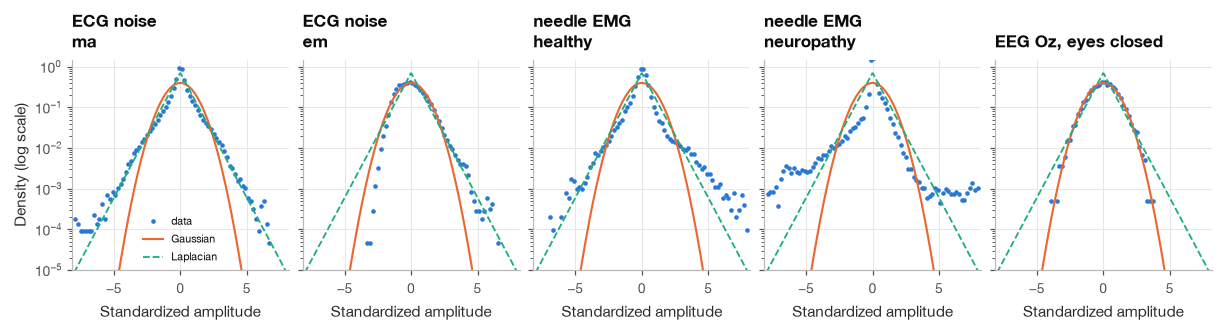

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(11, 2.9), sharey=True)
zgrid = np.linspace(-8, 8, 400)
for ax, (name, (x, unit)) in zip(axes, cleaned.items()):
    z = (x - x.mean()) / x.std()
    hist, edges = np.histogram(z, bins=80, range=(-8, 8), density=True)
    centres = 0.5 * (edges[1:] + edges[:-1])
    ax.semilogy(centres[hist > 0], hist[hist > 0], ".", color=C[0], ms=4, label="data")
    ax.semilogy(zgrid, stats.norm.pdf(zgrid), color=C[1], lw=1.4, label="Gaussian")
    ax.semilogy(zgrid, stats.laplace.pdf(zgrid, scale=1 / np.sqrt(2)), color=C[2], lw=1.2, ls="--", label="Laplacian")
    ax.set(xlabel="Standardized amplitude", title=name.replace(": ", "\n"), ylim=(1e-5, 1.5))
axes[0].set_ylabel("Density (log scale)")
axes[0].legend(loc="lower center", fontsize=7)
plt.show()

### Step 5: Interpret

The resting EEG is the most Gaussian of the five: its skewness and excess kurtosis are close to zero and its log-histogram follows the Gaussian parabola. This is the central limit theorem at work, since the scalp potential sums the activity of very large populations of neurons. Electrode motion artifact also behaves almost like Gaussian noise once its slow component is removed.

The other three recordings have positive excess kurtosis and tails far above the Gaussian curve. The muscle artifact `ma` is bursty, quiet between contractions and large during them, and an ECG preprocessing method that assumes Gaussian noise will underestimate how often large spikes occur. The needle EMG is the extreme case. A needle electrode records a small number of nearby motor units whose action potentials are brief spikes separated by quiet intervals, exactly the situation in which the central limit theorem does not apply. In neuropathy, surviving motor units take over denervated fibres and produce larger, rarer potentials, and the excess kurtosis rises further. The Laplacian is a better description than the Gaussian for these signals, although even it underestimates the extreme tails. I find this comparison one of the quickest sanity checks to run on any new type of recording, because it tells you in a minute whether Gaussian-based tools are likely to be appropriate.

## Summary

A random variable is described by its density, which we estimate from data with a normalized histogram or, without any bin choice, with the empirical CDF. The mean, variance, skewness and kurtosis summarize the density; the variance satisfies $\sigma^2 = \mathbb{E}[X^2] - \mu^2$ and scales as $a^2$ under amplification. The Gaussian, uniform and Laplacian densities model thermal noise, quantization noise ($\Delta^2/12$) and spiky signals, and they differ most in their tails, which the excess kurtosis (0, $-1.2$ and 3) captures. The central limit theorem explains why sums of many small independent contributions, such as the EEG, are close to Gaussian.

Covariance measures linear dependence; independence implies zero covariance but not conversely, as $Y = X^2$ shows. The variance of a sum includes twice the covariance, so for uncorrelated measurements the variance of the sample mean is $\sigma^2/N$, the foundation of confidence intervals and of signal averaging in [Section 10.1](../ch16_noise_removal/01_signal_averaging.ipynb). On real recordings, the EEG was nearly Gaussian while muscle artifact and needle EMG were strongly heavy-tailed. These ideas extend to whole signals in [Chapter 7](../ch12_spectral_estimation/index.md), where random processes, autocorrelation and the power spectral density take the place of single random variables.

## Exercises

1. A random variable has density $f_X(x) = 2x$ on $[0, 1]$ and zero elsewhere. Compute its CDF, mean, variance and $P(X > 0.5)$ by hand, and confirm them with $10^5$ samples generated as $X = \sqrt{U}$ with $U$ uniform on $[0, 1]$. Why does this transformation produce the right density?
2. Show that $\operatorname{Var}(aX + bY) = a^2\sigma_X^2 + b^2\sigma_Y^2 + 2ab\operatorname{Cov}(X, Y)$. An ECG lead is the difference of two electrode potentials whose noises have equal variance $\sigma^2$ and correlation $\rho$. What is the noise variance of the lead, and why does a large positive $\rho$ help?
3. Using $\int_0^\infty t^n e^{-t/b}\,dt = n!\,b^{n+1}$, verify the variance and the kurtosis of the Laplacian density in equation (2.36). Then compute $P(|X| > 3\sigma)$ exactly for the Gaussian and Laplacian densities and compare with the table in [Section 2.4.3](#sec-2-4-3).
4. An ADC with 12 bits spans $\pm 5$ mV. Compute the step $\Delta$ and the RMS quantization noise, and compare it with 10 µV of amplifier noise. Assuming independence, what is the total noise RMS? Check your answer by simulating both noises.
5. Estimate the excess kurtosis of sums of $N$ independent exponential variables for $N = 1, 2, 4, 8, 32$ and verify the $1/N$ law stated in [Section 2.4.4](#sec-2-4-4). How large must $N$ be before the skewness drops below 0.1?
6. The confidence interval for the mean RR interval of record 100 assumed independent intervals. Split the RR series into non-overlapping blocks of 50 beats, compute the mean of each block, and use the spread of the block means to estimate the standard error of the overall mean (the method of batch means). Compare with $s/\sqrt{N}$ and explain the difference using equation (2.38).

## Further Reading

{cite:t}`papoulis2002` is the classic engineering reference for probability, random variables and the central limit theorem, and {cite:t}`kay1988` and {cite:t}`bendat2010` connect these ideas to signal analysis. For a gentle statistical treatment aimed at biomedical data, {cite:t}`semmlow2014` is a good companion, and {cite:t}`bishop2006` (Chapter 2) gives a clear account of the Gaussian and related densities. The noise stress test database is described in {cite:t}`moody1984`, the EEG data in {cite:t}`schalk2004`, and all recordings are distributed through PhysioNet {cite:p}`goldberger2000`.